In [1]:
import pandas as pd
from datasets import Dataset
from transformers import RobertaTokenizer, RobertaForSequenceClassification, Trainer, TrainingArguments
import torch

In [2]:
file_path = "C:/Users/HENY/Downloads/SiH2025H/Dataset.csv"
df = pd.read_csv(file_path)

In [3]:
print("Sample data:")
print(df.head())

Sample data:
   sr.no                                               text       source  \
0      0  Produced by Chris Young Ritzen, Tamara Weitzma...  openwebtext   
1      1  Lawrence Eugene Doby (December 13, 1923 – June...  openwebtext   
2      2  Shock and Awe\n\nGabe Newell is about to make ...  openwebtext   
3      3  The Best Answers to Tough Interview Questions\...  openwebtext   
4      4                                                NaN  openwebtext   

      label_name  label_id  
0  human-written         1  
1  human-written         1  
2  human-written         1  
3  human-written         1  
4  human-written         1  


In [4]:
df = df[['text', 'label_id']]  # keep only useful columns
df = df.dropna()

In [5]:
df = df.rename(columns={'label_id': 'labels'})

In [6]:
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['labels'])

# Convert to Hugging Face Dataset format
train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)

In [7]:
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

# Tokenization function
def tokenize(batch):
    return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=256)

train_dataset = train_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(tokenize, batched=True)

train_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])
test_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])

C:\Users\HENY\Downloads\SiH2025H\.venv1\Lib\site-packages\huggingface_hub\file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Map:   0%|          | 0/9258 [00:00<?, ? examples/s]

Map:   0%|          | 0/2315 [00:00<?, ? examples/s]

In [8]:
model = RobertaForSequenceClassification.from_pretrained('roberta-base', num_labels=2)

C:\Users\HENY\Downloads\SiH2025H\.venv1\Lib\site-packages\huggingface_hub\file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.out_proj.bias', 'classifier.out_proj.weight', 'classifier.dense.weight', 'classifier.dense.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [9]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir='./results',
    do_train=True,
    do_eval=True,
    logging_dir='./logs',
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=10,
    learning_rate=2e-5,
    logging_steps=100,          # log every 100 steps
    eval_steps=500,             # evaluate every 500 steps
    evaluation_strategy="epoch",  # ✅ fixed name
    logging_strategy="epoch"      # ✅ normal space
)


In [10]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    tokenizer=tokenizer,
)

In [11]:
trainer.train()

C:\Users\HENY\Downloads\SiH2025H\.venv1\Lib\site-packages\transformers\optimization.py:411: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


Epoch,Training Loss,Validation Loss
1,0.324600,0.535156
2,0.207200,0.303315
3,0.146300,0.692025
4,0.094800,0.802130
5,0.066900,1.334129
6,0.053400,0.912552
7,0.037600,0.889374
8,0.027300,1.283685
9,0.017800,1.081896
10,0.014900,0.942623


TrainOutput(global_step=5790, training_loss=0.09906975345908052, metrics={'train_runtime': 3027.9364, 'train_samples_per_second': 30.575, 'train_steps_per_second': 1.912, 'total_flos': 1.21794107526144e+16, 'train_loss': 0.09906975345908052, 'epoch': 10.0})

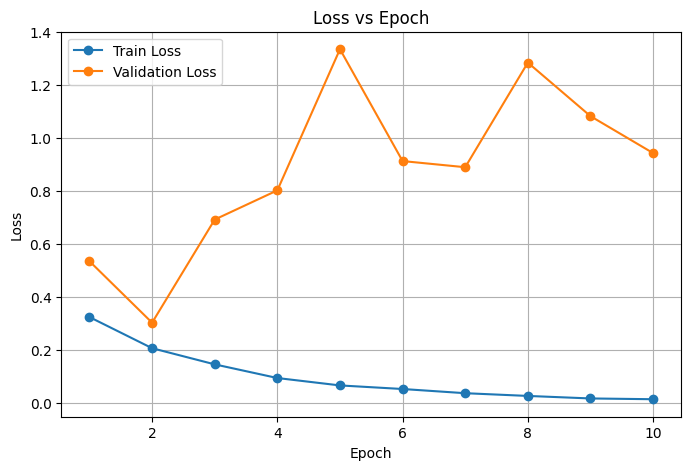

In [12]:
import matplotlib.pyplot as plt

# Extract log history
logs = trainer.state.log_history

# Separate metrics for training and validation
train_loss = [x['loss'] for x in logs if 'loss' in x and 'eval_loss' not in x]
eval_loss = [x['eval_loss'] for x in logs if 'eval_loss' in x]
accuracy = [x['eval_accuracy'] for x in logs if 'eval_accuracy' in x]

epochs_train = range(1, len(train_loss)+1)
epochs_eval = range(1, len(eval_loss)+1)

# Plot Loss
plt.figure(figsize=(8,5))
plt.plot(epochs_train, train_loss, label='Train Loss', marker='o')
plt.plot(epochs_eval, eval_loss, label='Validation Loss', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss vs Epoch')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
metrics = trainer.evaluate()
print("\nEvaluation results:")
print(metrics)


Evaluation results:
{'eval_loss': 0.9578934907913208, 'eval_runtime': 18.256, 'eval_samples_per_second': 126.807, 'eval_steps_per_second': 7.943, 'epoch': 10.0}


In [13]:
save_dir = "fine_tuned_roberta_ai_detector"
trainer.save_model(save_dir)
tokenizer.save_pretrained(save_dir)

print(f"\n✅ Model saved to: {save_dir}")



✅ Model saved to: fine_tuned_roberta_ai_detector



Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.98      0.90      1158
           1       0.98      0.79      0.87      1157

    accuracy                           0.89      2315
   macro avg       0.90      0.89      0.89      2315
weighted avg       0.90      0.89      0.89      2315



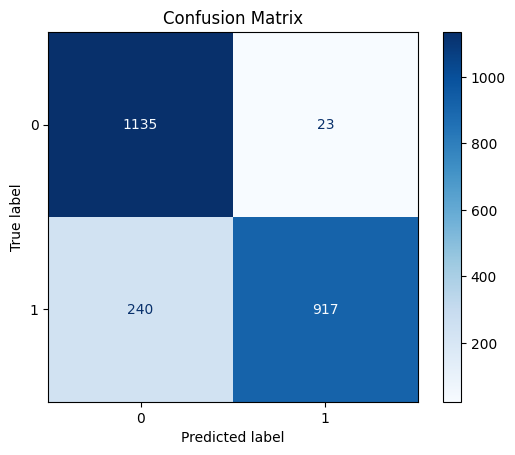

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
import numpy as np

# Get predictions on the test set
predictions = trainer.predict(test_dataset)

# Extract true and predicted labels
y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=1)

# Print detailed report
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

In [25]:
from transformers import pipeline

pipe = pipeline("text-classification", model=save_dir, tokenizer=save_dir)
sample_text = "Good Morning"
result = pipe(sample_text)
print("\n🔍 Prediction:")
print(result)

C:\Users\HENY\Downloads\SiH2025H\.venv1\Lib\site-packages\transformers\modeling_utils.py:460: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(checkpoint_file


🔍 Prediction:
[{'label': 'LABEL_0', 'score': 0.9999420642852783}]


In [20]:
model.push_to_hub("Henit007/text_detection", check_pr=True)

tokenizer.push_to_hub("Henit007/text_detection",check_pr=True)

pytorch_model.bin:   0%|          | 0.00/499M [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/Henit007/text_detection/commit/686ee1a8941bf4c99ce21614cc09fe3b94bcd37a', commit_message='Upload tokenizer', commit_description='', oid='686ee1a8941bf4c99ce21614cc09fe3b94bcd37a', pr_url=None, repo_url=RepoUrl('https://huggingface.co/Henit007/text_detection', endpoint='https://huggingface.co', repo_type='model', repo_id='Henit007/text_detection'), pr_revision=None, pr_num=None)

In [21]:
!hf upload Henit007/text_detection.

Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\HENY\Downloads\SiH2025H\.venv1\Scripts\hf.exe\__main__.py", line 7, in <module>
  File "C:\Users\HENY\Downloads\SiH2025H\.venv1\Lib\site-packages\huggingface_hub\cli\hf.py", line 57, in main
    service = args.func(args)
              ^^^^^^^^^^^^^^^
  File "C:\Users\HENY\Downloads\SiH2025H\.venv1\Lib\site-packages\huggingface_hub\cli\upload.py", line 186, in __init__
    raise ValueError(f"'{repo_name}' is not a local file or folder. Please set `local_path` explicitly.")
ValueError: 'text_detection.' is not a local file or folder. Please set `local_path` explicitly.


In [17]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Define a function to compute metrics
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)  # pick the class with highest probability
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc}

# When creating your Trainer
from transformers import Trainer, TrainingArguments

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics  # add this
)

# Evaluate
results = trainer.evaluate()
print(results)

{'eval_loss': 0.9578934907913208, 'eval_accuracy': 0.8863930885529158, 'eval_runtime': 18.6047, 'eval_samples_per_second': 124.431, 'eval_steps_per_second': 7.794}


In [18]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import Trainer, TrainingArguments

# Define a function to compute metrics
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)  # pick the class with highest probability
    acc = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics  # computes metrics
)

# Evaluate
results = trainer.evaluate()

# Print metrics including validation loss
print("Validation Loss:", results['eval_loss'])
print("Accuracy:", results['eval_accuracy'])
print("Precision:", results['eval_precision'])
print("Recall:", results['eval_recall'])
print("F1 Score:", results['eval_f1'])

Validation Loss: 0.9578934907913208
Accuracy: 0.8863930885529158
Precision: 0.8999287430443238
Recall: 0.8863930885529158
F1 Score: 0.8854184956417127


In [26]:
import streamlit as st
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.nn.functional import softmax
import pandas as pd
import time
import io
import PyPDF2
import docx

# --- Page Configuration ---
st.set_page_config(
    page_title="AI Text Detector",
    page_icon="🤖",
    layout="wide",
    initial_sidebar_state="expanded"
)

# --- Model Loading ---
# Cache the model and tokenizer to avoid reloading on every interaction.
@st.cache(allow_output_mutation=True)
def load_model_and_tokenizer():
    """Loads the pre-trained model and tokenizer."""
    model_name = "Henit007/text_detection"
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        model = AutoModelForSequenceClassification.from_pretrained(model_name)
        return tokenizer, model
    except Exception as e:
        st.error(f"Error loading model: {e}")
        return None, None

tokenizer, model = load_model_and_tokenizer()

# --- Classification Function ---
def classify_text(text: str):
    """
    Classifies the input text as AI-generated or not and returns detailed results.
    """
    if not text.strip():
        return None, None, None

    # Tokenize the input text
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)

    # Ensure the model is in evaluation mode
    model.eval()

    # Perform inference
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits

    # Apply softmax to get probabilities
    probs = softmax(logits, dim=1).squeeze().tolist()

    # Get the predicted class index
    predicted_class_id = torch.argmax(logits).item()

    # Map the output to the corresponding label
    label_map = {0: "AI-Generated", 1: "Human-Written"}
    predicted_label = label_map[predicted_class_id]

    return predicted_label, probs, text

# --- UI Layout ---

# Sidebar for instructions and information
with st.sidebar:
    st.image("https://placehold.co/400x200/000000/FFFFFF?text=AI+Detector", use_column_width=True)
    st.header("How It Works")
    st.markdown("""
    This tool uses a machine learning model (Henit007/text_detection) to predict whether a piece of text was written by a human or generated by an AI.

    1.  *Enter Text*: Paste your text into the text box on the main page, or upload a .txt, .pdf, or .docx file.
    2.  *Analyze*: Click the 'Analyze Text' button.
    3.  *Get Results*: The app will display the prediction and the model's confidence scores.

    *Disclaimer:* This is a predictive tool and not always 100% accurate. It should be used as an indicator rather than a definitive judgment.
    """)
    st.info("Created for demonstration purposes.")


# Main page layout
st.title("🤖 AI vs. Human Text Detector")
st.write("Is your text written by a human or generated by AI? Let's find out.")

# Create two columns for input methods
col1, col2 = st.columns(2)

with col1:
    st.subheader("📝 Paste Text Here")
    text_input = st.text_area("Enter the text you want to analyze:", height=300, key="text_area")

with col2:
    st.subheader("📂 Or Upload a File")
    uploaded_file = st.file_uploader("Choose a .txt, .pdf, or .docx file", type=["txt", "pdf", "docx"])

# Analyze button
if st.button("Analyze Text", type="primary", use_container_width=True):
    final_text = ""
    if text_input.strip():
        final_text = text_input
    elif uploaded_file is not None:
        try:
            file_extension = uploaded_file.name.split('.')[-1].lower()

            if file_extension == "txt":
                final_text = uploaded_file.getvalue().decode("utf-8")

            elif file_extension == "pdf":
                pdf_reader = PyPDF2.PdfReader(io.BytesIO(uploaded_file.getvalue()))
                text_parts = [page.extract_text() for page in pdf_reader.pages if page.extract_text()]
                final_text = "\n".join(text_parts)

            elif file_extension == "docx":
                document = docx.Document(io.BytesIO(uploaded_file.getvalue()))
                final_text = "\n".join([para.text for para in document.paragraphs])

        except Exception as e:
            st.error(f"Error processing file '{uploaded_file.name}': {e}")
            final_text = ""

    if final_text and tokenizer and model:
        # Show a spinner while processing
        with st.spinner('Analyzing the text... This may take a moment.'):
            time.sleep(1) # Simulate a short delay for better UX
            label, probabilities, analyzed_text = classify_text(final_text)

        st.divider()
        st.header("Analysis Results")

        if label:
            # Display the result with a prominent label and icon
            if label == "AI-Generated":
                st.error("Prediction: This text is likely AI-Generated 🤖", icon="🚨")
            else:
                st.success("Prediction: This text is likely Human-Written 🧑‍💻", icon="✅")

            # Display probabilities in a more detailed view
            st.subheader("Confidence Score")
            st.write("The model assigns the following probabilities to each category:")

            # Create a dataframe for the bar chart
            prob_df = pd.DataFrame({
                'Category': ['AI-Generated', 'Human-Written'],
                'Probability': probabilities
            })

            # Use Streamlit's bar chart
            st.bar_chart(prob_df.set_index('Category'))

            # Display detailed probabilities
            prob_col1, prob_col2 = st.columns(2)
            with prob_col1:
                st.metric(label="AI-Generated Probability", value=f"{probabilities[0]:.2%}")
            with prob_col2:
                st.metric(label="Human-Written Probability", value=f"{probabilities[1]:.2%}")

            # Show the analyzed text in an expander
            with st.expander("Show Analyzed Text"):
                st.text_area("", analyzed_text, height=250, disabled=True)
        else:
            st.warning("The text could not be analyzed. Please ensure it is not empty or the file could be read.")
    else:
        if not tokenizer or not model:
            st.error("Model is not loaded. Cannot perform analysis.")
        else:
            st.warning("Please enter some text or upload a file to analyze.")

2025-10-14 21:26:35.242 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-14 21:26:35.248 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-14 21:26:35.419 
  command:

    streamlit run C:\Users\HENY\Downloads\SiH2025H\.venv1\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2025-10-14 21:26:35.420 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-14 21:26:35.420 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-14 21:26:35.421 
`st.cache` is deprecated and will be removed soon. Please use one of Streamlit's new
caching commands, `st.cache_data` or `st.cache_resource`. More information
[in our docs](https://docs.streamlit.io/develop/concepts/architecture/caching).

**Note**: The beha

tokenizer_config.json: 0.00B [00:00, ?B/s]

C:\Users\HENY\Downloads\SiH2025H\.venv1\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HENY\.cache\huggingface\hub\models--Henit007--text_detection. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/763 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


pytorch_model.bin:   0%|          | 0.00/499M [00:00<?, ?B/s]

C:\Users\HENY\Downloads\SiH2025H\.venv1\Lib\site-packages\transformers\modeling_utils.py:460: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(checkpoint_file